In [5]:
######################################################################################################
# ALUNO : Daniel Marques Diniz Maia
# MATRÍCULA : 2026061836
# TURMA : TM
######################################################################################################

In [6]:
######################################################################################################################
#  ATIVIDADE PARA A PRÓXIMA AULA: 
#
#  1) GERAR DISTRIBUIÇÕES ALEATÓRIAS UNIFORME E GAUSSIANA (vetores)
#  2) Mostrar em um gráfico tipo histograma que a distribuição é realmente uniforme ou gaussiana (visualmente)
#  3) Criar um código (jogo???) que utilize números aleatórios!
#  4) Implemente um código utilizando o método "Linear Congruential Generator" e repita os testes acima 
#  para este. 
#  5) Explore o gerador de números aleatorios reais www.random.org
#  6) Usando o Linear Congruential Generator e a transformação de Box-Muller crie uma distribuição gaussiana
#   de números pseudo-aleatórios
# 
######################################################################################################################

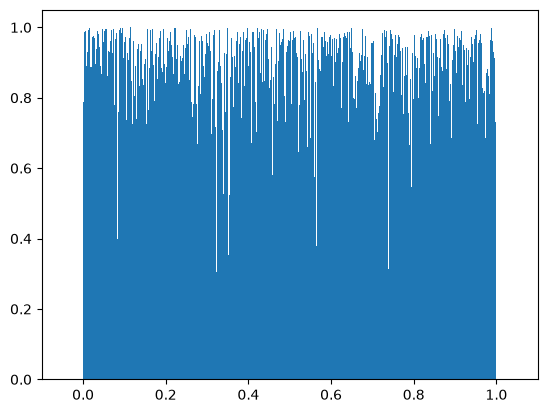

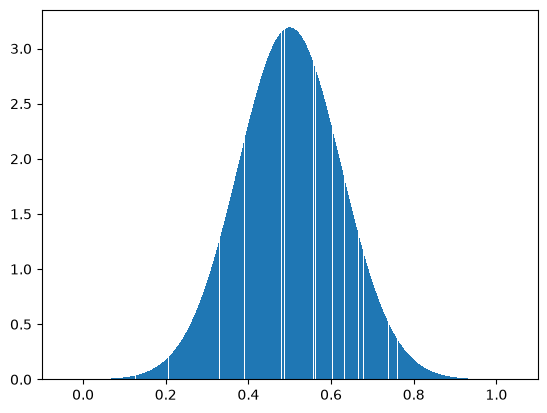

In [7]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from numpy.random import seed, rand, randn, randint



seed(12)

# Distribuição uniforme 100000 x 100000
x = rand(100000)
y = rand(100000)


fig, ax = plt.subplots()
ax.bar(x,y, 0.0001)
plt.xlim(-0.1,1.1)
plt.show()

# Distribuição Gaussiana 100000 x 100000
x = randn(100000)
y =np.exp(-np.power(x - 0.5, 2)*32)/(0.125*np.sqrt(2*np.pi))


fig, ax = plt.subplots()
ax.bar(x,y, 0.0001)
plt.xlim(-0.1,1.1)
plt.show()



In [8]:
def roleta_de_nota(matricula):
    # função atribui a um aluno uma nota  de 0 a 100 aleatoriamente utilizando seu número de matrícula
    indices =[randint(0,10) for _ in range(1,9)]
    nota1 = 10*int(matricula[indices[0]]) + int(matricula[indices[1]]) + int(matricula[indices[2]])/10 + int(matricula[indices[3]])/100
    nota2 = 10*int(matricula[indices[4]]) + int(matricula[indices[5]]) + int(matricula[indices[6]])/10 + int(matricula[indices[7]])/100
    return (nota1+nota2)/2
for _ in range(0,15):
    print(roleta_de_nota('2026061836'))

17.67
30.370000000000005
31.110000000000003
18.32
46.239999999999995
16.44
11.66
27.3
36.145
13.91
13.0
51.33
20.725
34.349999999999994
31.360000000000003


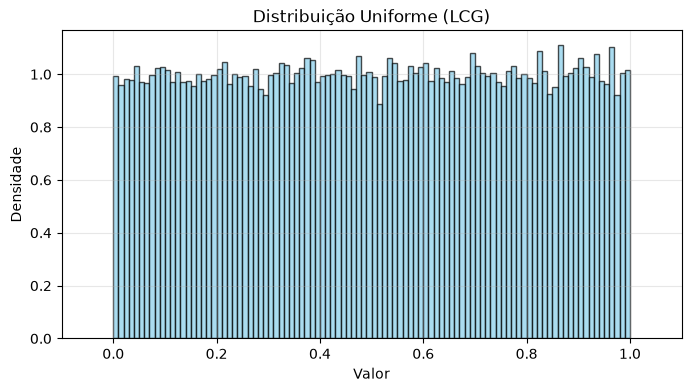

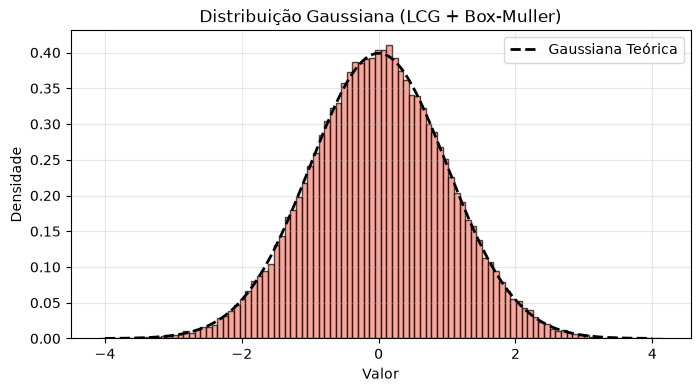

In [9]:
# Linear Congruential Generator (LCG)
def lcg(n, seed=12):
    # Parâmetros clássicos (usados pelo glibc / ANSI C)
    m = 2**31
    a = 1103515245
    c = 12345
    
    numbers = np.zeros(n)
    state = seed
    
    for i in range(n):
        state = (a * state + c) % m
        numbers[i] = state / m  # Normaliza para o intervalo [0, 1)
        
    return numbers

# Transformação de Box-Muller
def box_muller(u1, u2):
    # Evita log(0) adicionando uma constante pequena se necessário
    z0 = np.sqrt(-2.0 * np.log(u1)) * np.cos(2.0 * np.pi * u2)
    z1 = np.sqrt(-2.0 * np.log(u1)) * np.sin(2.0 * np.pi * u2)
    return z0, z1

# Distribuição Uniforme usando LCG 
N = 100000
x_lcg = lcg(N, seed=12)

plt.figure(figsize=(8, 4))
plt.hist(x_lcg, bins=100, density=True, alpha=0.7, color='skyblue', edgecolor='black')
plt.title('Distribuição Uniforme (LCG)')
plt.xlabel('Valor')
plt.ylabel('Densidade')
plt.xlim(-0.1, 1.1)
plt.grid(True, alpha=0.3)
plt.show()

# Distribuição Gaussiana usando LCG + Box-Muller
u1 = lcg(N, seed=12)
u2 = lcg(N, seed=42)  # Semente diferente para garantir independência

z0, _ = box_muller(u1, u2)

plt.figure(figsize=(8, 4))
plt.hist(z0, bins=100, density=True, alpha=0.7, color='salmon', edgecolor='black')

# Curva teórica da Gaussiana N(0,1) para comparação
x_axis = np.linspace(-4, 4, 1000)
gaussiana_teorica = (1 / np.sqrt(2 * np.pi)) * np.exp(-0.5 * x_axis**2)
plt.plot(x_axis, gaussiana_teorica, 'k--', linewidth=2, label='Gaussiana Teórica')

plt.title('Distribuição Gaussiana (LCG + Box-Muller)')
plt.xlabel('Valor')
plt.ylabel('Densidade')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()